# 04 · Precipitation → Soil-Moisture Lag Analysis

**Objective.** How long after rain does soil moisture respond, and does rainfall couple
more tightly to **5 cm** than **20 cm** moisture? This is a *correlation* study of the
physical signal — a motivation for the rain features, **not** a measure of CNN skill.

**Provenance & reproducibility**

- **Results shown here:** 🔄 **computed fresh in this notebook** from the raw dataset via `src.features.precip_lag_correlation` — not from the Nov-17 CSVs. (Saved copies used by the report live in `results/P1_lag_correlations.csv` and `results/P4_lag_depth_comparison.csv`.)
- **Experimental setup:** Hourly `Ppt` vs `SWC_20` and `SWC_5` at the 4 study stations; lags 0–72 h; correlation with the *cumulative* moisture change out to t+lag.
- **Implementation:** `src.features.precip_lag_correlation` (pure NumPy; see `src/features.py`).
- **Original code:** this is a diagnostic computed directly from the data; no CNN training is involved.
- **Reproduce:** Run the cells (CPU, ~20 s).

In [1]:
# --- project setup: portable across local / Google Drive / fresh Colab ---
import os, sys

def find_project_root(marker="src"):
    # 1) walk up from the current directory (local checkout or Drive upload)
    p = os.path.abspath(os.getcwd())
    while p != os.path.dirname(p):
        if os.path.isdir(os.path.join(p, marker)):
            return p
        p = os.path.dirname(p)
    # 2) common Colab upload locations
    for c in ("/content/soil_moisture_research",
              "/content/drive/MyDrive/soil_moisture_research"):
        if os.path.isdir(os.path.join(c, marker)):
            return c
    raise FileNotFoundError(
        "Could not find the project root (a folder containing 'src/').\n"
        "Upload the whole soil_moisture_research/ folder to Drive/Colab and "
        "open this notebook from inside notebooks/.")

ROOT = find_project_root()
sys.path.insert(0, ROOT)
os.chdir(ROOT)
print("project root set ->", os.path.basename(ROOT))  # portable: no absolute path

project root set -> soil_moisture_research


In [2]:
import pandas as pd
from src.data_processing import load_dataframe
from src.features import precip_lag_correlation
from src import config as C
df = load_dataframe()
LAGS = (0,1,2,3,6,12,24,48,72)
out = []
for s in C.SELECTED_STATIONS:
    g = df[df.Station==s].sort_values('Timestamp')
    for depth in ['SWC_20','SWC_5']:
        lc = precip_lag_correlation(g, target=depth, lags=LAGS)
        lc.insert(0,'station',s); lc.insert(1,'depth',depth); out.append(lc)
lag = pd.concat(out, ignore_index=True)
lag[lag.station=='FD02'].pivot(index='lag_h', columns='depth', values='corr_cumulative').round(3)

depth,SWC_20,SWC_5
lag_h,,
0,NaN,NaN
1,0.297,0.556
2,0.334,0.449
3,0.333,0.357
6,0.294,0.216
12,0.219,0.118
24,0.171,0.054
48,0.116,0.002
72,0.086,-0.021


### Figures (saved to `figures/` and `report/figures/`)

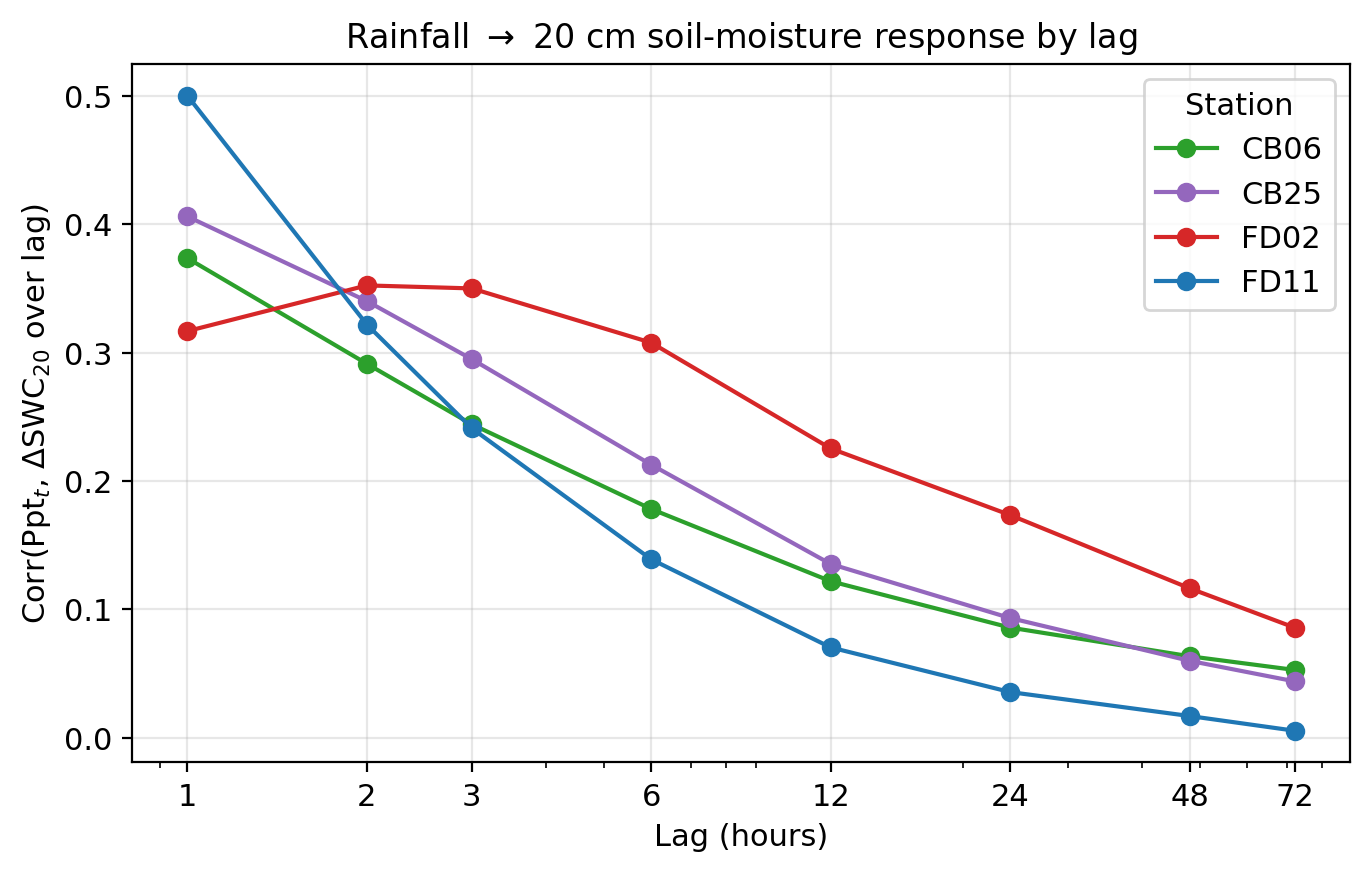

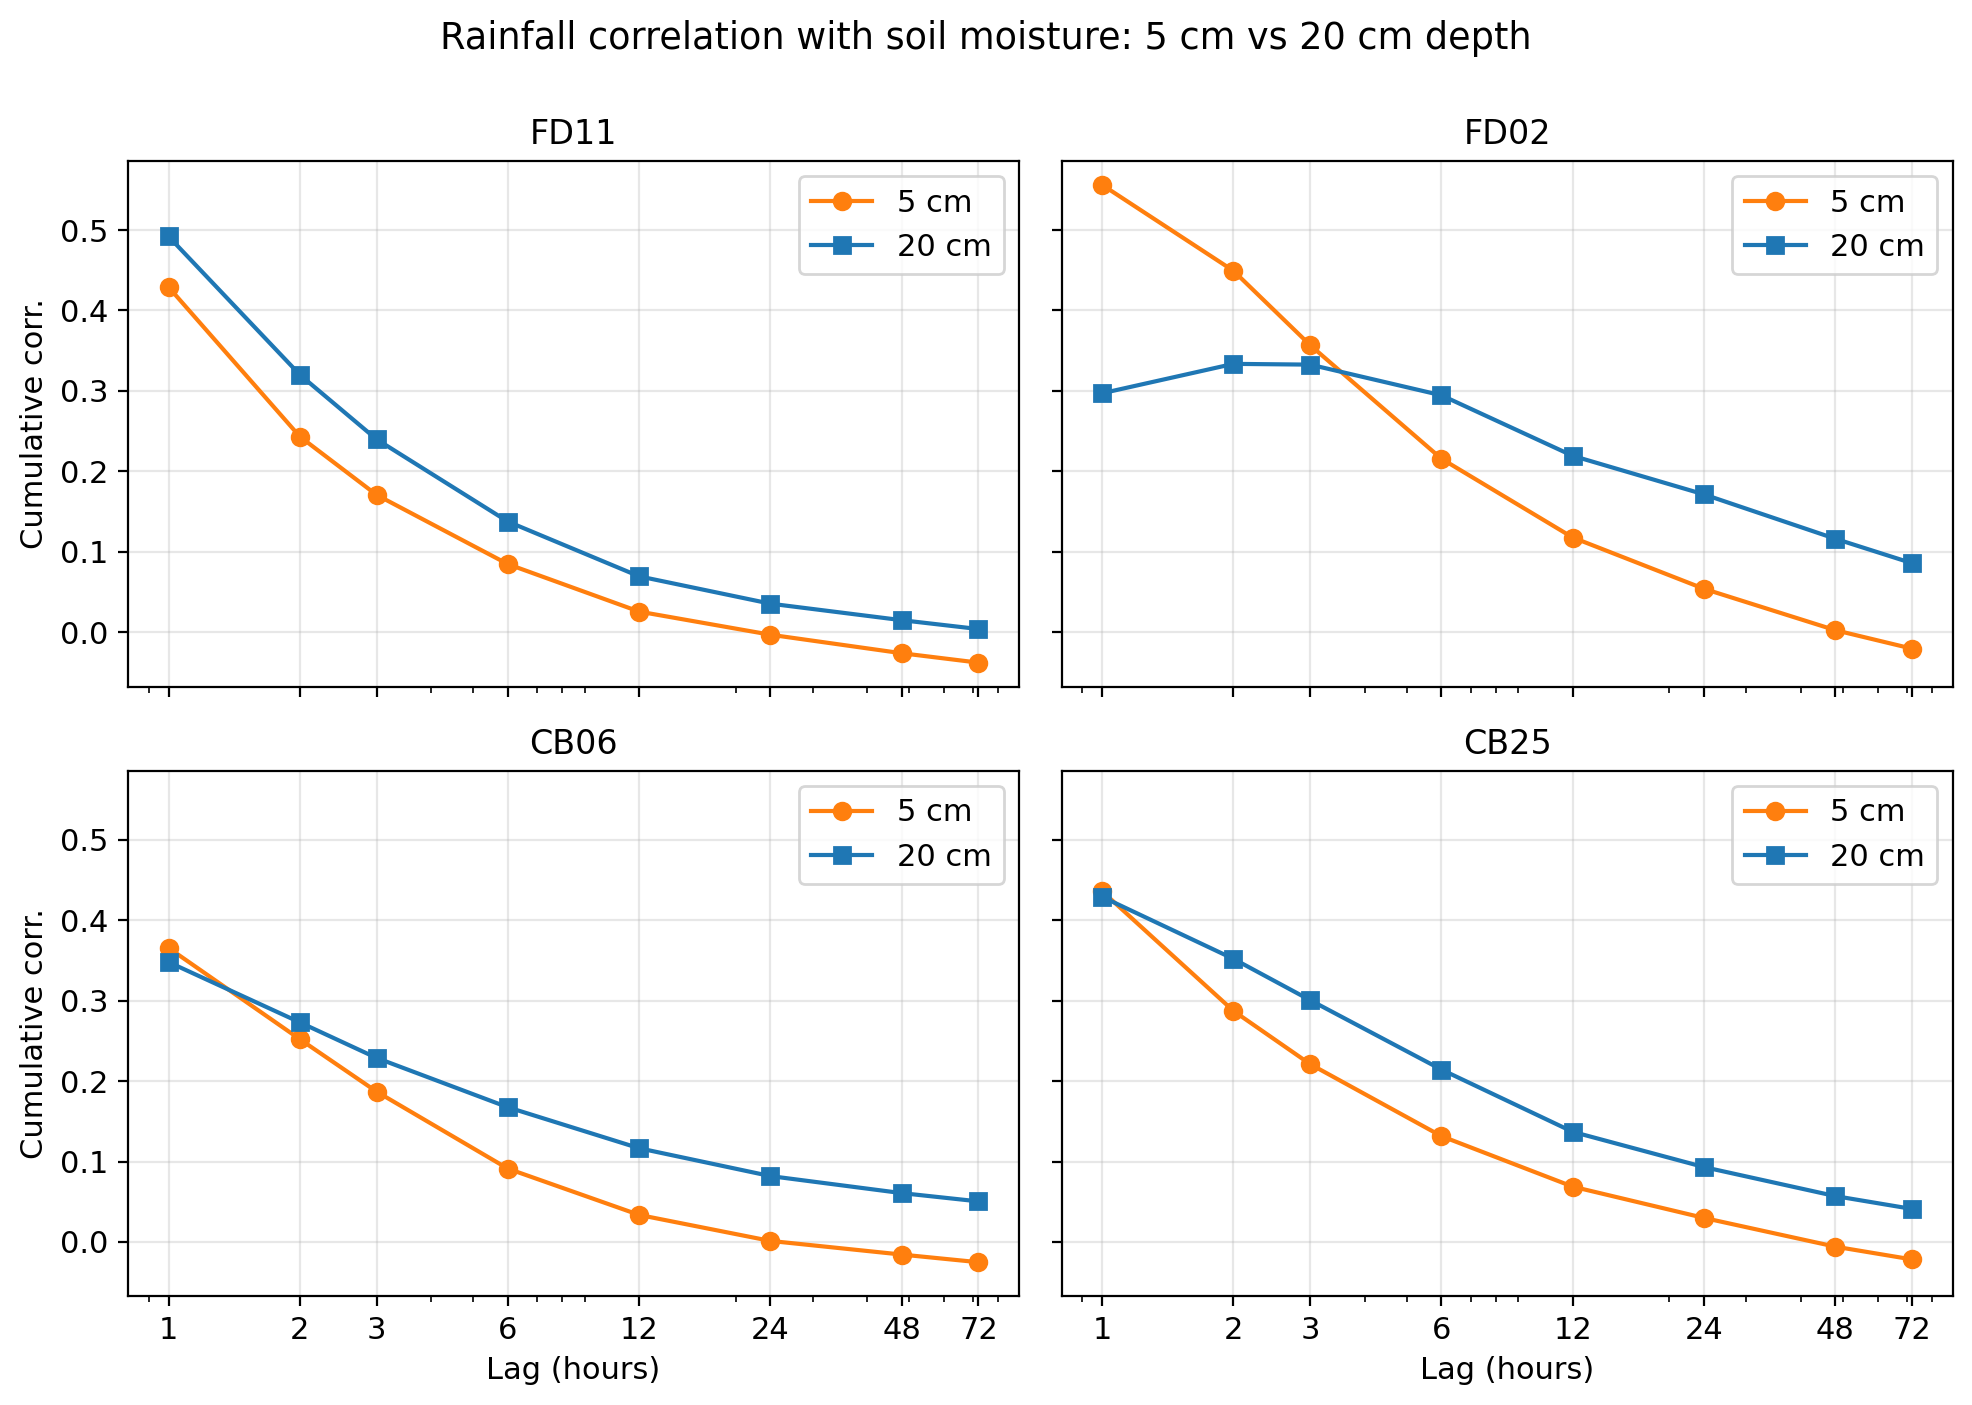

In [3]:
from IPython.display import Image, display
display(Image('figures/fig_p1_lag_correlation.png'))
display(Image('figures/fig_p4_lag_depth.png'))

**Takeaways.** The rainfall→moisture response peaks at a **1–2 hour** lag and decays
within a day. Depth coupling is station-dependent: at the driest station (FD02) rain
correlates far more with 5 cm (r≈0.56) than 20 cm (r≈0.33), but at FD11 the ordering
reverses. **Caveat (important for the research question):** a strong rain↔moisture
correlation here does **not** imply that rain features improve the CNN's `SWC_20`
forecast — notebook 07 shows they generally do not. Correlation ≠ predictive gain.